### Libraries Installation

In [1]:
!pip install -r requirements.txt

### Import Common Libraries

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Initial Understanding about the Dataset

In [3]:
df = pd.read_csv("./dataset/train.csv")

In [4]:
df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
848,849,FDT10,16.700,Regular,0.062045,Snack Foods,57.4562,Epic,OUT046,1997,Small,Tier 1,Supermarket Type1,948.0992
2902,2903,NCJ30,5.820,Low Fat,0.000000,Household,169.3790,Epic,OUT013,1987,High,Tier 3,Supermarket Type1,2376.9060
5215,5216,FDJ08,11.100,Low Fat,0.111123,Fruits and Vegetables,189.2846,GardaWorld,OUT018,2009,Medium,Tier 3,Supermarket Type2,3630.6074
6571,6572,FDP56,8.185,Low Fat,0.046747,Fruits and Vegetables,49.9692,Prosegur,OUT017,2007,NaN,Tier 2,Supermarket Type1,837.5764
913,914,FDM56,NaN,Low Fat,0.122896,Fruits and Vegetables,111.1912,G4S,OUT019,1985,Small,Tier 1,Grocery Store,218.3824


In [5]:
pd.set_option("display.float_format", "{:.4f}".format)
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8540.0000,7074.0000,8540.0000,8540.0000,8540.0000,8540.0000
mean,4270.5000,36.9014,9072.7391,5004.0879,1998.0057,26730.3951
std,2465.4300,2004.8743,838424.9445,386410.2548,20.0632,1383157.7150
min,1.0000,-87523.0000,0.0000,-13479.0000,1876.0000,-7976.7286
25%,2135.7500,8.7700,0.0270,93.8021,1987.0000,830.9184
50%,4270.5000,12.6000,0.0539,143.0312,1999.0000,1794.3310
75%,6405.2500,16.8500,0.0946,185.7562,2004.0000,3101.2964
max,8540.0000,98032.0000,77480627.0000,35127361.0000,3678.0000,99999999.0000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   No             8540 non-null   int64  
 1   ID             8540 non-null   object 
 2   Weight         7074 non-null   float64
 3   Fat            8540 non-null   object 
 4   Visibility     8540 non-null   float64
 5   Category       8540 non-null   object 
 6   Price          8540 non-null   float64
 7   Security       8540 non-null   object 
 8   StoreCode      8540 non-null   object 
 9   OperationYear  8540 non-null   int64  
 10  Size           6125 non-null   object 
 11  Area           8540 non-null   object 
 12  Type           8540 non-null   object 
 13  Sales          8540 non-null   float64
dtypes: float64(4), int64(2), object(8)
memory usage: 934.2+ KB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["ID"].unique().size

1562

In [9]:
df["Fat"].unique()

array(['Low Fat', 'Regular', 'low fat', 'LF', 'reg'], dtype=object)

In [10]:
df["Category"].unique()

array(['Dairy', 'Soft Drinks', 'Meat', 'Fruits and Vegetables',
       'Household', 'Baking Goods', 'Snack Foods', 'Frozen Foods',
       'Breakfast', 'Health and Hygiene', 'Hard Drinks', 'Canned',
       'Breads', 'Starchy Foods', 'Others', 'Seafood'], dtype=object)

In [11]:
df["Size"].unique()

array(['Medium', nan, 'High', 'Small'], dtype=object)

In [12]:
df["Area"].unique()

array(['Tier 1', 'Tier 3', 'Tier 2'], dtype=object)

In [13]:
df["Type"].unique()

array(['Supermarket Type1', 'Supermarket Type2', 'Grocery Store',
       'Supermarket Type3'], dtype=object)

In [14]:
df["StoreCode"].unique()

array(['OUT049', 'OUT018', 'OUT010', 'OUT013', 'OUT027', 'OUT045',
       'OUT017', 'OUT046', 'OUT035', 'OUT019'], dtype=object)

In [15]:
df["ID"].unique()

array(['FDA15', 'DRC01', 'FDN15', ..., 'NCW30', 'NCW05', 'FDY78'],
      shape=(1562,), dtype=object)

In [16]:
df["ID"].str[:3].unique()

array(['FDA', 'DRC', 'FDN', 'FDX', 'NCD', 'FDP', 'FDO', 'FDH', 'FDU',
       'FDY', 'FDS', 'FDF', 'NCB', 'DRI', 'FDW', 'FDC', 'FDR', 'FDV',
       'DRJ', 'FDE', 'NCS', 'DRH', 'NCX', 'DRZ', 'FDB', 'FDK', 'FDL',
       'FDM', 'NCP', 'NCL', 'DRK', 'FDI', 'FDZ', 'NCI', 'FDJ', 'FDG',
       'NCZ', 'FDQ', 'FDD', 'DRG', 'NCR', 'FDT', 'DRB', 'DRE', 'DRA',
       'NCF', 'NCH', 'NCO', 'NCN', 'NCC', 'DRD', 'DRF', 'DRL', 'NCM',
       'NCU', 'DRY', 'NCW', 'DRM', 'NCT', 'NCQ', 'DRP', 'DRQ', 'NCK',
       'NCY', 'DRN', 'NCA', 'NCE', 'NCJ', 'NCV', 'NCG', 'DRO', 'NDL'],
      dtype=object)

## Preprocessing of Sales Column (Target)

In [17]:
df["Sales"].describe()

count       8540.0000
mean       26730.3951
std      1383157.7150
min        -7976.7286
25%          830.9184
50%         1794.3310
75%         3101.2964
max     99999999.0000
Name: Sales, dtype: float64

In [18]:
low_sales = df.nsmallest(5, "Sales")
high_sales = df.nlargest(5, "Sales")

display(high_sales)
display(low_sales)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
5180,5181,FDY90,-7832.0000,Regular,0.0819,Fruits and Vegetables,6423746.0000,Brinks,OUT049,1999,Medium,Tier 1,Supermarket Type1,99999999.0000
6047,6048,FDM24,98032.0000,Regular,0.0793,Baking Goods,35127361.0000,Allied Universal,OUT035,2004,Small,Tier 2,Supermarket Type1,67612861.0000
6193,6194,FDF39,14.8500,Regular,0.0196,Dairy,263.7910,Epic,OUT045,2002,NaN,Tier 2,Supermarket Type1,42079856.0000
7202,7203,NCE42,NaN,Low Fat,0.0106,Household,234.9958,Epic,OUT027,1985,Medium,Tier 3,Supermarket Type3,13086.9648
5233,5234,FDQ19,NaN,Regular,0.0143,Fruits and Vegetables,242.6512,Allied Universal,OUT027,1985,Medium,Tier 3,Supermarket Type3,12117.5600


,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
6360,6361,FDC28,7.9050,Low Fat,0.0551,Frozen Foods,109.2254,Brinks,OUT045,2002,NaN,Tier 2,Supermarket Type1,-7976.7286
8078,8079,NCN29,15.2000,Low Fat,0.0121,Health and Hygiene,48.7034,Prosegur,OUT045,2002,NaN,Tier 2,Supermarket Type1,-5680.4476
8438,8439,FDV19,14.8500,Regular,0.0353,Fruits and Vegetables,161.2578,Prosegur,OUT046,1997,Small,Tier 1,Supermarket Type1,-4171.9028
6658,6659,FDO21,11.6000,Regular,0.0098,Snack Foods,226.9404,Epic,OUT035,2004,Small,Tier 2,Supermarket Type1,-1800.3232
908,909,DRK12,9.5000,Low Fat,0.0000,Soft Drinks,32.8900,Prosegur,OUT010,1998,NaN,Tier 3,Grocery Store,33.2900


In [19]:
# Convert negative sales into positive values
df.loc[df["Sales"] < 0, "Sales"] = (
    df.loc[df["Sales"] < 0, "Sales"].abs()
)

In [20]:
# Remove two corrupted observations
df = df.drop(index=[5180, 6047])

In [21]:
# Replace the third extreme Sales value with median
df.loc[6193, "Sales"] = df["Sales"].median()

In [22]:
df["Sales"].describe()

count    8538.0000
mean     2181.5310
std      1707.8673
min        33.2900
25%       831.4178
50%      1794.3310
75%      3101.2964
max     13086.9648
Name: Sales, dtype: float64

<Axes: ylabel='Sales'>

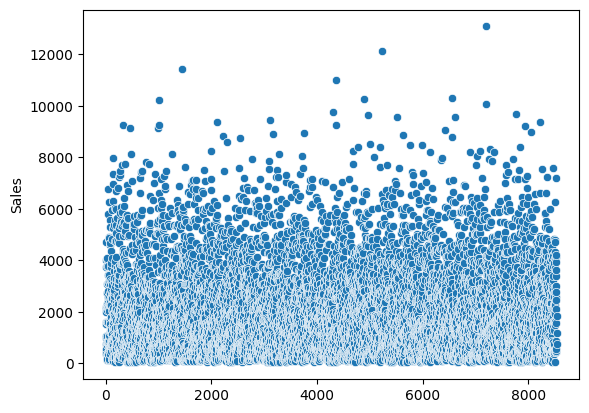

In [23]:
sns.scatterplot(df["Sales"])

## Exploratory Data Analysis

### Univariate Analysis

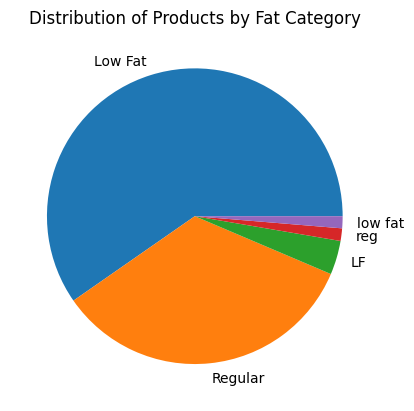

In [24]:
plt.pie(df["Fat"].value_counts(), labels=df["Fat"].value_counts().index)
plt.title("Distribution of Products by Fat Category")
plt.show()

<Axes: xlabel='OperationYear', ylabel='count'>

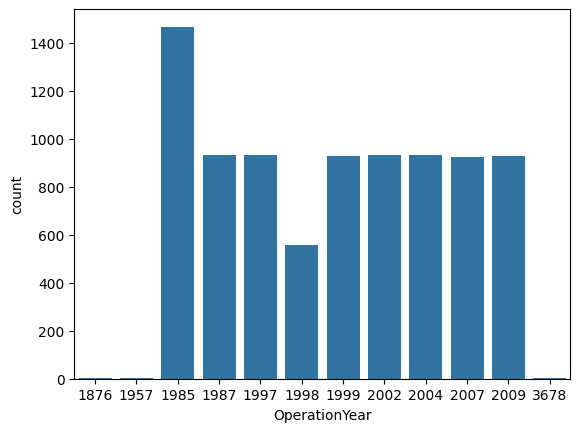

In [25]:
sns.barplot(df["OperationYear"].value_counts())

<Axes: ylabel='Category'>

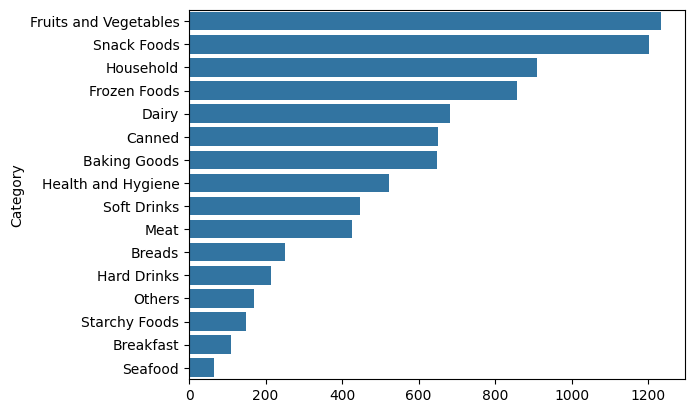

In [26]:
sns.barplot(x=df["Category"].value_counts().values, y=df["Category"].value_counts().index)

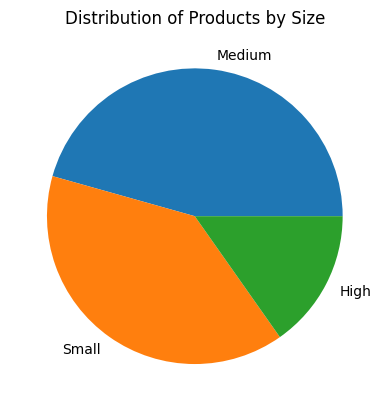

In [27]:
plt.pie(df["Size"].value_counts(), labels=df["Size"].value_counts().index)
plt.title("Distribution of Products by Size")
plt.show()

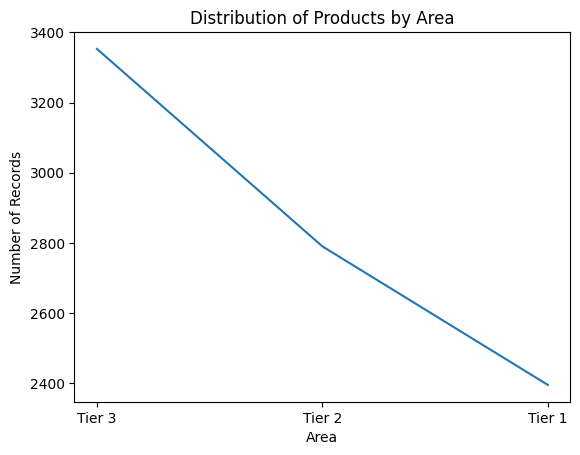

In [28]:
plt.plot(df["Area"].value_counts())
plt.title("Distribution of Products by Area")
plt.xlabel("Area")
plt.ylabel("Number of Records")
plt.show()

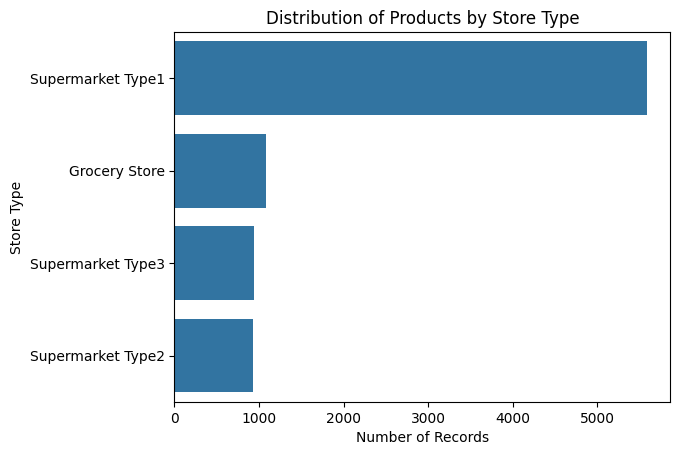

In [29]:
sns.barplot(x=df["Type"].value_counts(), y=df["Type"].value_counts().index)
plt.title("Distribution of Products by Store Type")
plt.xlabel("Number of Records")
plt.ylabel("Store Type")
plt.show()

<Axes: xlabel='Price', ylabel='Count'>

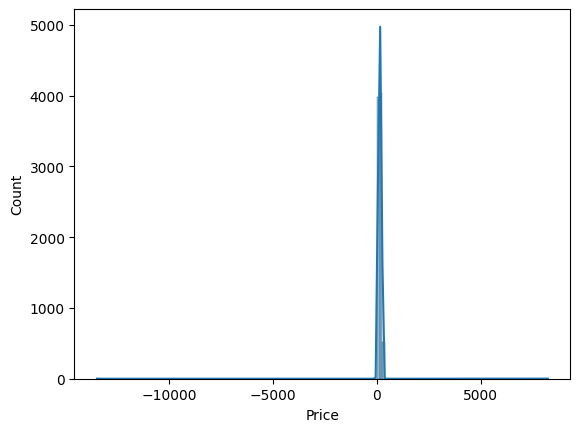

In [30]:
sns.histplot(df["Price"], kde=True)

<Axes: xlabel='Weight', ylabel='Count'>

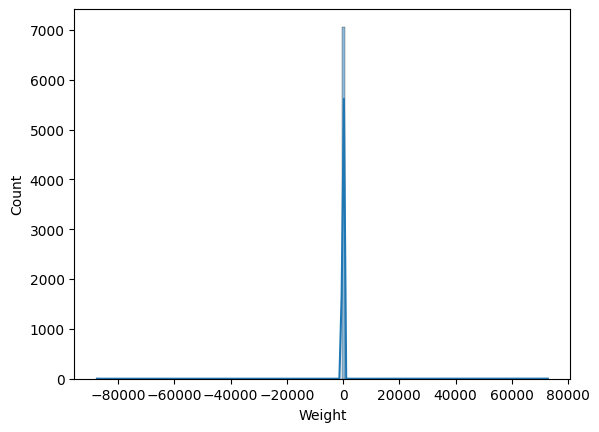

In [31]:
sns.histplot(df["Weight"], kde=True)

In [32]:
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8538.0000,7072.0000,8538.0000,8538.0000,8538.0000,8538.0000
mean,4270.1852,24.1573,9074.8643,138.6512,1998.0049,2181.5310
std,2465.6240,1629.0030,838523.1380,218.2607,20.0654,1707.8673
min,1.0000,-87523.0000,0.0000,-13479.0000,1876.0000,33.2900
25%,2135.2500,8.7700,0.0270,93.7876,1987.0000,831.4178
50%,4269.5000,12.6000,0.0539,143.0141,1999.0000,1794.3310
75%,6405.7500,16.8500,0.0946,185.6845,2004.0000,3101.2964
max,8540.0000,72816.3500,77480627.0000,8224.0000,3678.0000,13086.9648


<Axes: ylabel='Weight'>

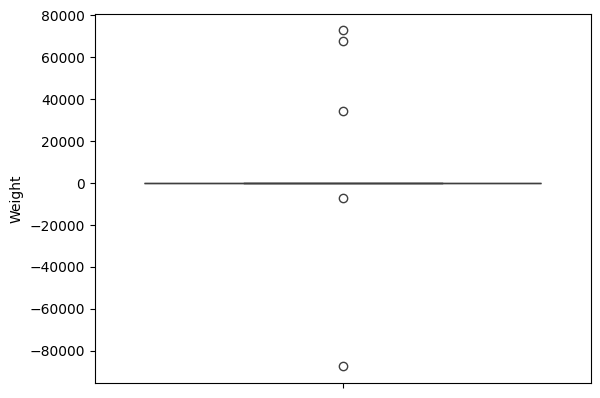

In [33]:
sns.boxplot(df["Weight"])

<Axes: ylabel='Price'>

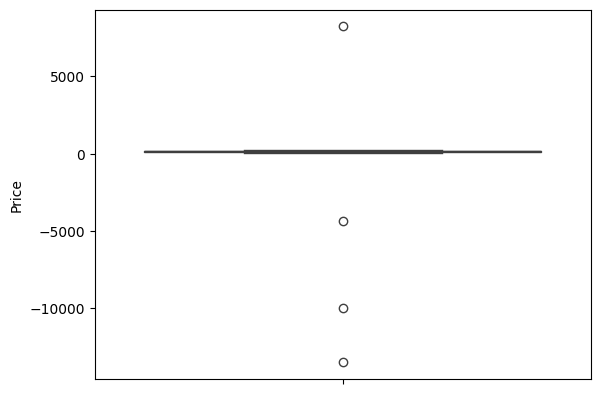

In [34]:
sns.boxplot(df["Price"])

<Axes: ylabel='StoreCode'>

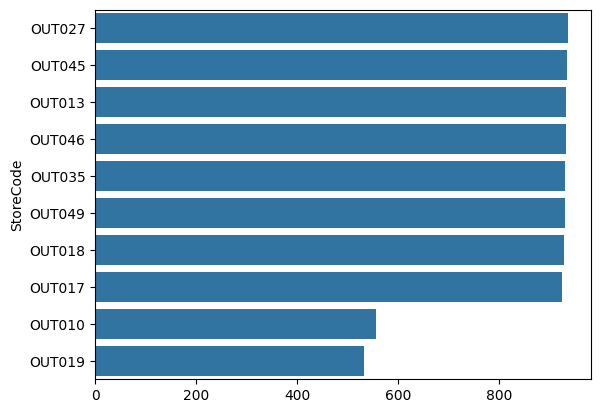

In [35]:
sns.barplot(x=df["StoreCode"].value_counts().values, y=df["StoreCode"].value_counts().index)

<Axes: ylabel='Visibility'>

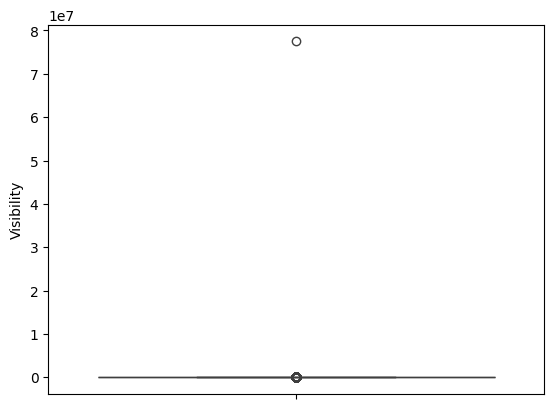

In [36]:
sns.boxplot(df["Visibility"])

<Axes: ylabel='Sales'>

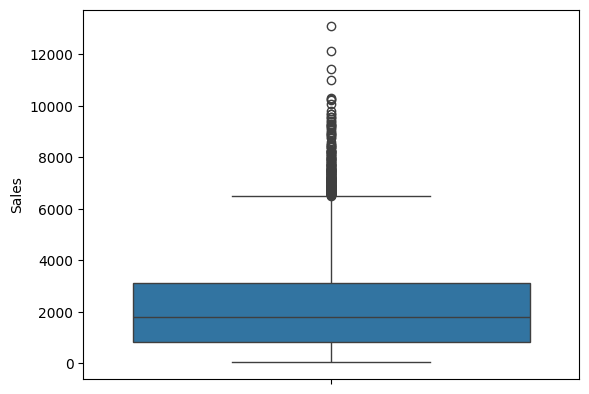

In [37]:
df["Sales"].describe()
sns.boxplot(df["Sales"])

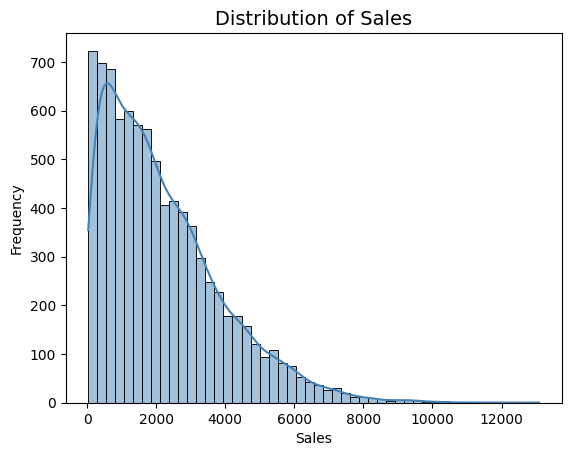

In [38]:
sns.histplot(
    data=df,
    x="Sales",
    bins=50,
    kde=True,
    color="steelblue"
)
plt.title("Distribution of Sales", fontsize=14)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

### Bi-Variate Analysis

In [39]:
df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
3529,3530,FDM56,16.7000,Low Fat,0.0000,Fruits and Vegetables,109.1912,NSPS,OUT018,2009,Medium,Tier 3,Supermarket Type2,545.9560
4519,4520,FDR35,12.5000,Low Fat,0.0207,Breads,198.8742,Prosegur,OUT046,1997,Small,Tier 1,Supermarket Type1,5773.1518
8008,8009,FDB23,19.2000,Regular,0.0000,Starchy Foods,223.8062,NSPS,OUT045,2002,NaN,Tier 2,Supermarket Type1,5642.6550
7799,7800,FDE11,17.7000,Regular,0.1350,Starchy Foods,184.4924,Prosegur,OUT013,1987,High,Tier 3,Supermarket Type1,3146.5708
3757,3758,NCZ18,NaN,Low Fat,0.3258,Household,252.7698,Epic,OUT019,1985,Small,Tier 1,Grocery Store,761.0094


<Axes: xlabel='Weight', ylabel='Sales'>

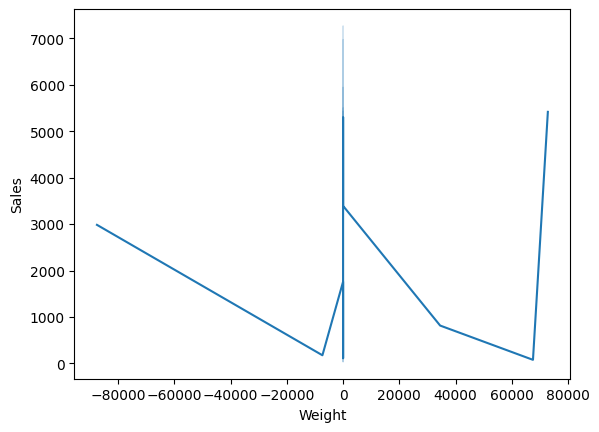

In [40]:
sns.lineplot(x=df["Weight"], y=df["Sales"])

<Axes: xlabel='Weight', ylabel='Sales'>

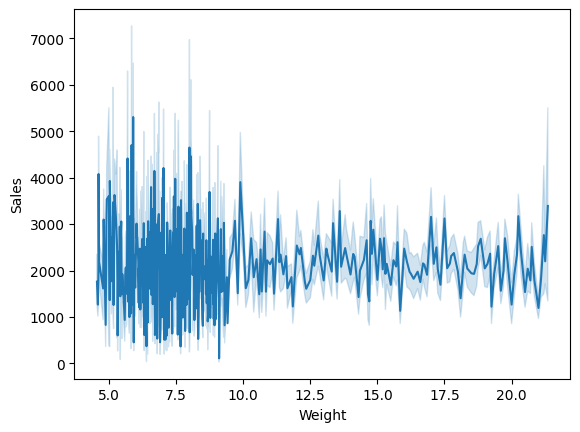

In [41]:
df_temp = df[df["Weight"] > 0]
df_temp = df_temp[df_temp["Weight"] < 100]
sns.lineplot(data=df_temp, x="Weight", y="Sales")
# Negative Weight need to remove
# Scaling is needed

<Axes: xlabel='Fat', ylabel='Sales'>

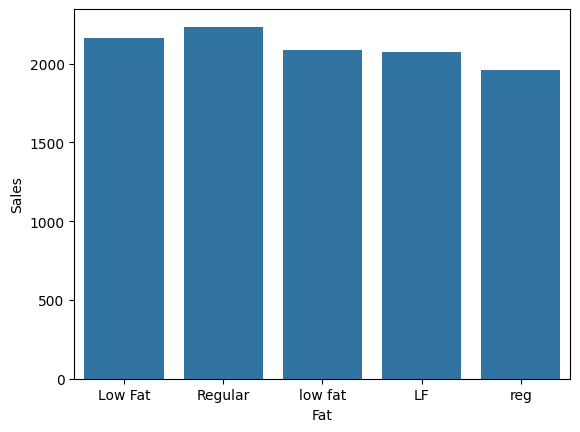

In [42]:
sns.barplot(data=df, x="Fat", y="Sales", errorbar=None)

#Low Fat + low fat Fat + LF and reg + regular need to combine

<Axes: xlabel='Fat', ylabel='Sales'>

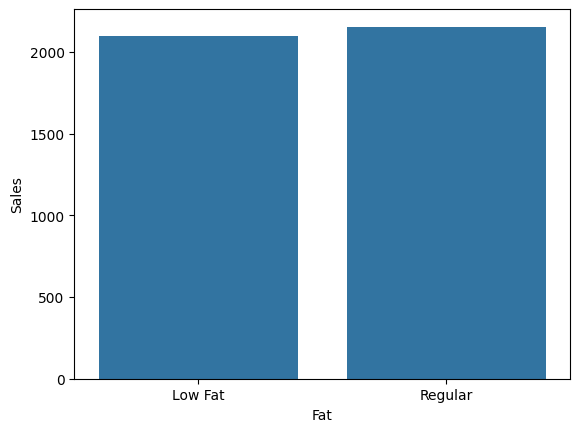

In [43]:
df_temp["Fat"] = df["Fat"].replace({
    "low fat": "Low Fat",
    "LF": "Low Fat",
    "reg": "Regular"
})

sns.barplot(data=df_temp, x="Fat", y="Sales", errorbar=None)

<Axes: xlabel='Visibility', ylabel='Sales'>

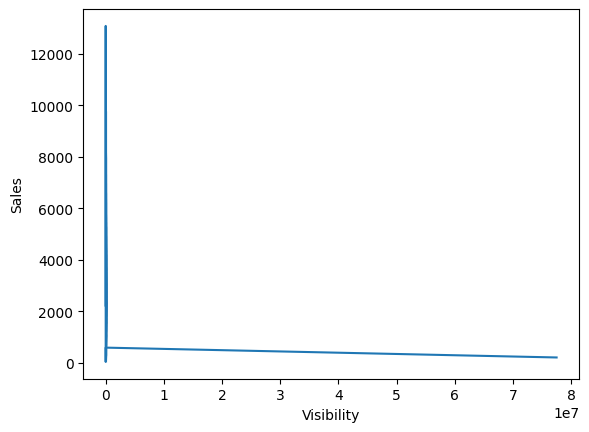

In [44]:
sns.lineplot(data=df, x="Visibility", y="Sales")

# Visibility contains large values need to remove

<Axes: xlabel='Visibility', ylabel='Sales'>

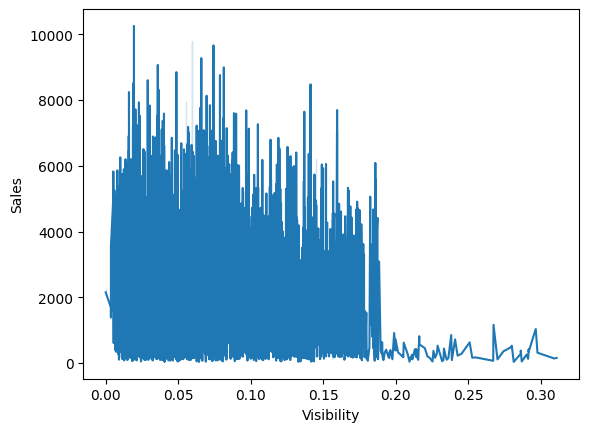

In [45]:
df_temp=df_temp[df_temp["Visibility"] < 10]
sns.lineplot(data=df_temp, x="Visibility", y="Sales")

<Axes: xlabel='Price', ylabel='Sales'>

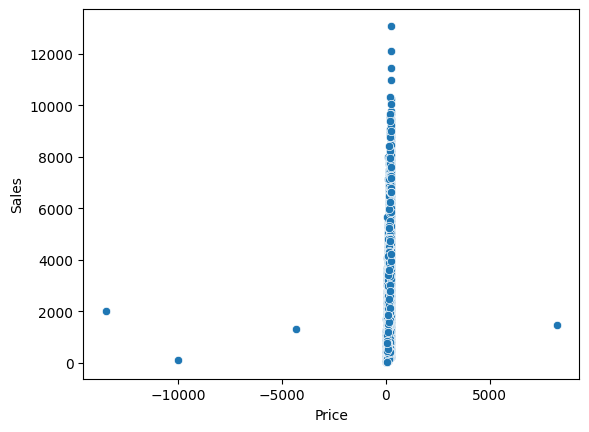

In [46]:
sns.scatterplot(data=df, x="Price", y="Sales")

<Axes: xlabel='Price', ylabel='Sales'>

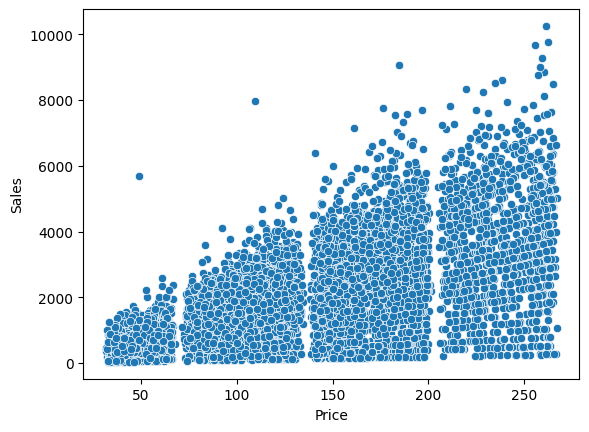

In [47]:
df_temp = df_temp[df_temp["Price"] > 0]
sns.scatterplot(data=df_temp, x="Price", y="Sales")

<Axes: ylabel='StoreCode'>

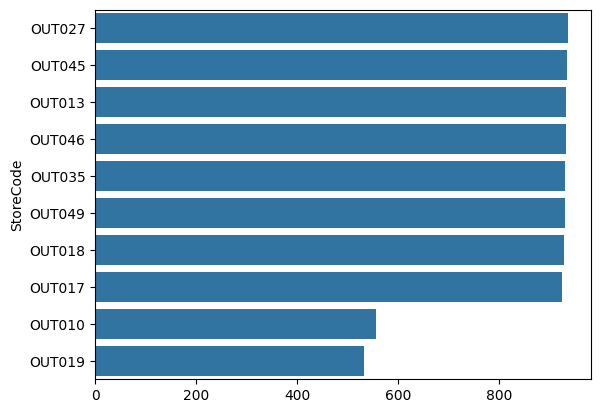

In [48]:
sns.barplot(x=df["StoreCode"].value_counts().values, y=df["StoreCode"].value_counts().index)

<Axes: xlabel='OperationYear', ylabel='Sales'>

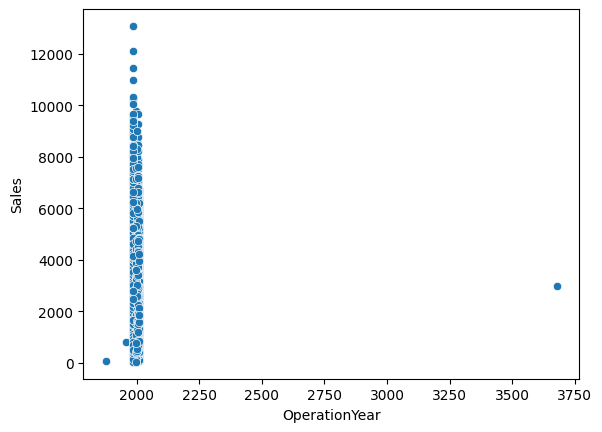

In [49]:
sns.scatterplot(data=df, x="OperationYear", y="Sales")

In [50]:
df_temp.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,7064.0000,7064.0000,7064.0000,7064.0000,7064.0000,7064.0000
mean,4254.7288,12.8578,0.0639,141.2579,2000.4907,2120.2132
std,2455.3225,4.6427,0.0486,62.4305,6.5870,1535.3772
min,1.0000,4.5550,0.0000,31.4900,1987.0000,33.2900
25%,2139.7500,8.7737,0.0267,94.1436,1997.0000,922.7988
50%,4233.5000,12.6000,0.0525,142.7483,2002.0000,1789.6704
75%,6373.2500,16.8500,0.0927,186.0247,2007.0000,2970.1338
max,8540.0000,21.3500,0.3111,266.8884,2009.0000,10256.6490


<Axes: xlabel='OperationYear', ylabel='Sales'>

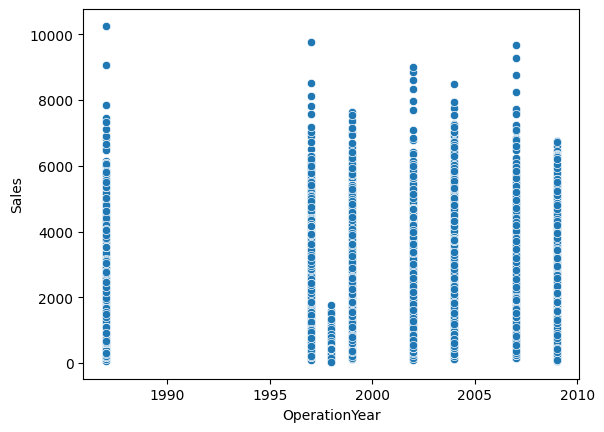

In [51]:
df_temp = df_temp[df_temp["OperationYear"] >= 1985]
df_temp = df_temp[df_temp["OperationYear"] <= 2026]
sns.scatterplot(data=df_temp, x="OperationYear", y="Sales")

<Axes: xlabel='Area', ylabel='Sales'>

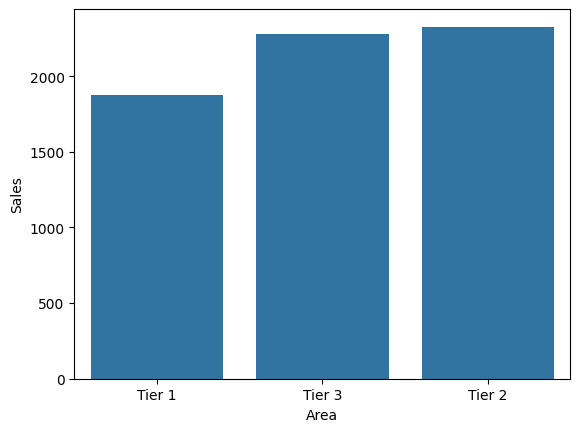

In [52]:
sns.barplot(data=df, x="Area", y="Sales", errorbar=None)

<Axes: xlabel='Sales', ylabel='Type'>

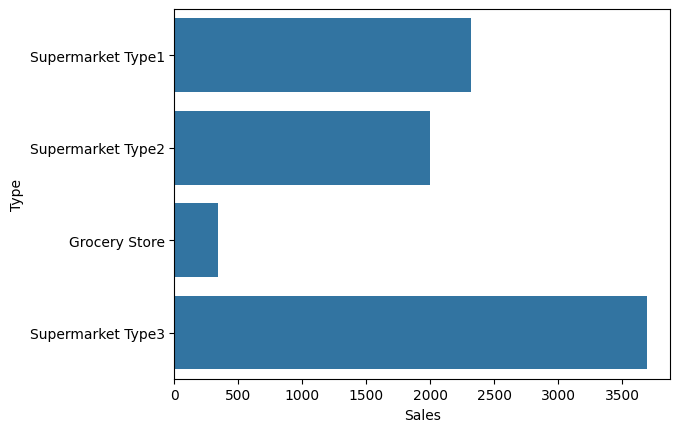

In [53]:
sns.barplot(data=df, y="Type", x="Sales", errorbar=None, orient="h")

<Axes: xlabel='Sales', ylabel='Category'>

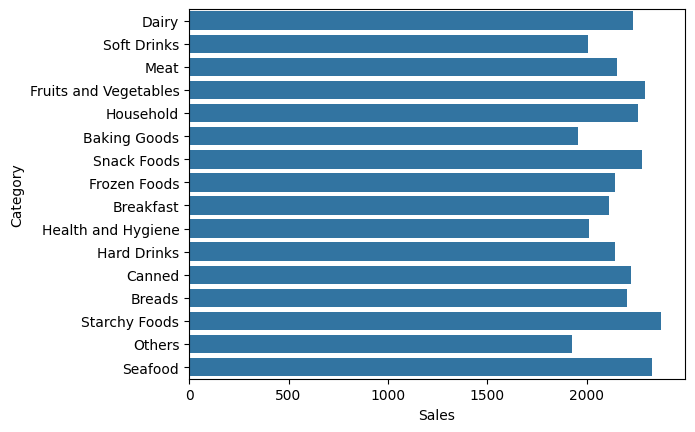

In [54]:
sns.barplot(data=df, y="Category", x="Sales", errorbar=None, orient="h")

<Axes: xlabel='Sales', ylabel='Size'>

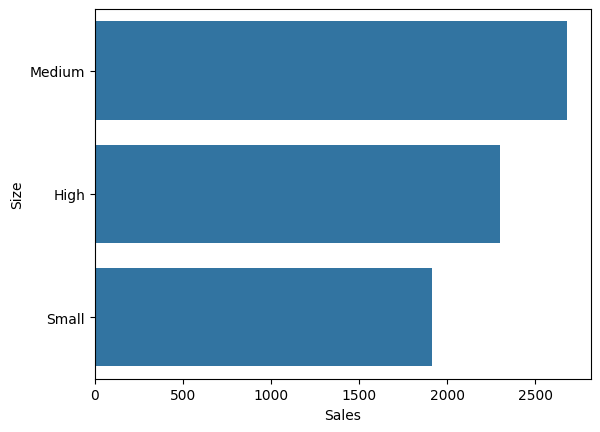

In [55]:
sns.barplot(data=df, y="Size", x="Sales", errorbar=None, orient="h")

### Multivariate Analysis

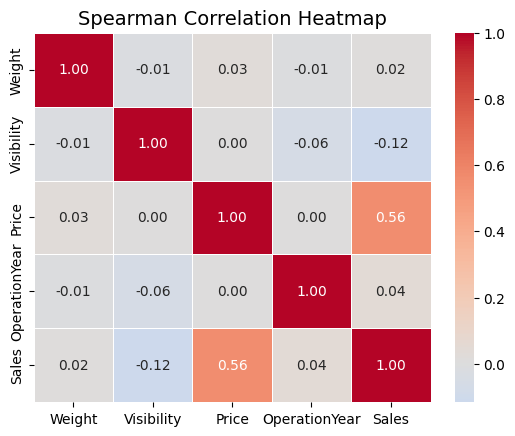

In [56]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

numeric_df = numeric_df.drop(
    columns=["No"],
    errors="ignore"
)
correlation_matrix = numeric_df.corr(method="spearman")
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)
plt.title("Spearman Correlation Heatmap", fontsize=14)
plt.show()

<Axes: xlabel='Size', ylabel='count'>

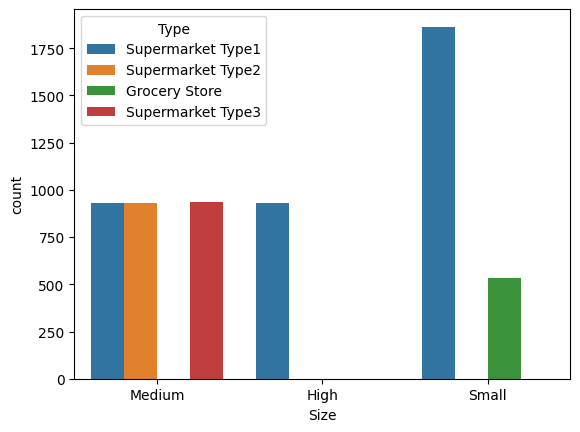

In [57]:
sns.countplot(data=df, x="Size", hue="Type")

<Axes: xlabel='Type', ylabel='count'>

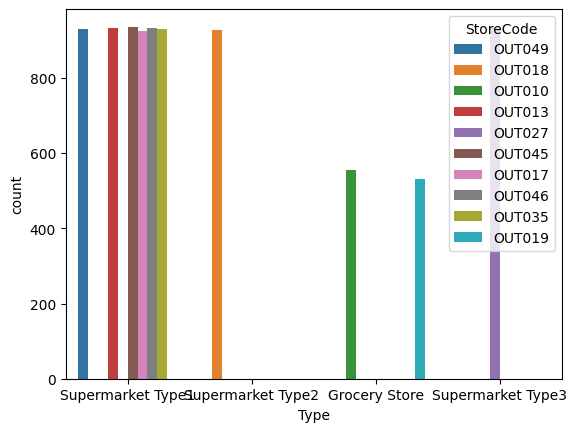

In [58]:
sns.countplot(data=df,x="Type", hue="StoreCode")

<Axes: xlabel='Type', ylabel='Sales'>

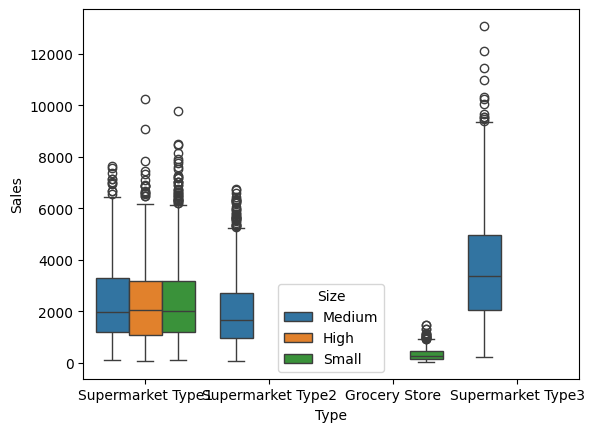

In [59]:
sns.boxplot( data=df, x="Type", y="Sales", hue="Size")

## Understanding the data

In [60]:
df.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,8538.0000,7072.0000,8538.0000,8538.0000,8538.0000,8538.0000
mean,4270.1852,24.1573,9074.8643,138.6512,1998.0049,2181.5310
std,2465.6240,1629.0030,838523.1380,218.2607,20.0654,1707.8673
min,1.0000,-87523.0000,0.0000,-13479.0000,1876.0000,33.2900
25%,2135.2500,8.7700,0.0270,93.7876,1987.0000,831.4178
50%,4269.5000,12.6000,0.0539,143.0141,1999.0000,1794.3310
75%,6405.7500,16.8500,0.0946,185.6845,2004.0000,3101.2964
max,8540.0000,72816.3500,77480627.0000,8224.0000,3678.0000,13086.9648


In [61]:
df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
1927,1928,FDL39,NaN,Regular,0.0630,Dairy,181.6318,NSPS,OUT027,1985,Medium,Tier 3,Supermarket Type3,1263.0226
1723,1724,NCF42,17.3500,Low Fat,0.1681,Household,176.2712,Prosegur,OUT018,2009,Medium,Tier 3,Supermarket Type2,1230.3984
1609,1610,FDG02,7.8550,Low Fat,0.0113,Canned,189.5188,Brinks,OUT046,1997,Small,Tier 1,Supermarket Type1,1904.1880
4982,4983,FDT50,6.7500,Regular,0.0000,Dairy,96.7752,AHS,OUT049,1999,Medium,Tier 1,Supermarket Type1,1342.2528
2816,2817,FDR60,14.3000,Low Fat,0.1303,Baking Goods,75.7328,G4S,OUT013,1987,High,Tier 3,Supermarket Type1,617.8624


In [62]:
df[df["Price"] <= 0].size

42

In [63]:
df[df["Weight"] <= 0].size

28

In [64]:
df[(df["Weight"] <= 0) & (df["Price"] <= 0)].size

0

In [65]:
df[(df["Weight"] <= 0) | (df["Price"] <= 0)].size

70

In [66]:
df.nlargest(5, "Visibility")

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
3458,3459,FDQ27,NaN,Regular,77480627.0000,Meat,101.3990,Brinks,OUT019,1985,Small,Tier 1,Grocery Store,206.3980
856,857,FDU13,NaN,low fat,0.3284,Canned,146.0418,Allied Universal,OUT019,1985,Small,Tier 1,Grocery Store,588.5672
3757,3758,NCZ18,NaN,Low Fat,0.3258,Household,252.7698,Epic,OUT019,1985,Small,Tier 1,Grocery Store,761.0094
1808,1809,FDJ56,NaN,Low Fat,0.3211,Fruits and Vegetables,100.7700,Brinks,OUT019,1985,Small,Tier 1,Grocery Store,199.7400
7264,7265,FDT24,12.3500,Regular,0.3111,Baking Goods,79.2328,G4S,OUT010,1998,NaN,Tier 3,Grocery Store,154.4656


In [67]:
df_temp.describe()

,No,Weight,Visibility,Price,OperationYear,Sales
count,7064.0000,7064.0000,7064.0000,7064.0000,7064.0000,7064.0000
mean,4254.7288,12.8578,0.0639,141.2579,2000.4907,2120.2132
std,2455.3225,4.6427,0.0486,62.4305,6.5870,1535.3772
min,1.0000,4.5550,0.0000,31.4900,1987.0000,33.2900
25%,2139.7500,8.7737,0.0267,94.1436,1997.0000,922.7988
50%,4233.5000,12.6000,0.0525,142.7483,2002.0000,1789.6704
75%,6373.2500,16.8500,0.0927,186.0247,2007.0000,2970.1338
max,8540.0000,21.3500,0.3111,266.8884,2009.0000,10256.6490


In [68]:
df.nlargest(5, "Weight")

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
536,537,FDY56,72816.3500,Regular,0.0624,Fruits and Vegetables,225.9062,Prosegur,OUT046,1997,Small,Tier 1,Supermarket Type1,5416.9488
3058,3059,NDL41,67523.0000,Low Fat,0.1246,Health and Hygiene,24.4267,Epic,OUT019,1876,Small,Tier 1,Grocery Store,78.3216
925,926,FDQ24,34510.0000,Low Fat,0.0453,Health and Hygiene,134.5600,GardaWorld,OUT013,1957,High,Tier 3,Supermarket Type1,816.1928
43,44,FDC02,21.3500,Low Fat,0.0691,Canned,259.9278,AHS,OUT018,2009,Medium,Tier 3,Supermarket Type2,6768.5228
484,485,FDC02,21.3500,Low Fat,0.1152,Canned,258.3278,Epic,OUT010,1998,NaN,Tier 3,Grocery Store,520.6556


In [69]:
df[df["OperationYear"] < 1985]

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
925,926,FDQ24,34510.0000,Low Fat,0.0453,Health and Hygiene,134.5600,GardaWorld,OUT013,1957,High,Tier 3,Supermarket Type1,816.1928
3058,3059,NDL41,67523.0000,Low Fat,0.1246,Health and Hygiene,24.4267,Epic,OUT019,1876,Small,Tier 1,Grocery Store,78.3216


In [70]:
(df["Size"]).value_counts()

Size
Medium    2794
Small     2396
High       933
Name: count, dtype: int64

In [71]:
(df["Size"])

0       Medium
1       Medium
2       Medium
3          NaN
4         High
         ...  
8535      High
8536       NaN
8537     Small
8538    Medium
8539     Small
Name: Size, Length: 8538, dtype: object

In [72]:
df["ID"].unique()

array(['FDA15', 'DRC01', 'FDN15', ..., 'NCW30', 'NCW05', 'FDY78'],
      shape=(1561,), dtype=object)

In [73]:
pattern = r"^[A-Z]{3}\d{2}$"

df["ID"].str.match(pattern).all()

np.True_

## Train-Test Split

In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(df.drop("Sales", axis=1), df["Sales"], test_size=0.2, random_state=42)

df.shape, X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((8538, 14), (6830, 13), (1708, 13), (6830,), (1708,))

## Machine Learning Pipeline

### 1.) Finding Useful Features

In [75]:
df.sample(1)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
6931,6932,FDK55,18.5000,Low Fat,0.0259,Meat,87.7172,Allied Universal,OUT017,2007,NaN,Tier 2,Supermarket Type1,802.9548


In [76]:
from sklearn.preprocessing import FunctionTransformer

trf1 = FunctionTransformer(
    lambda x: x.drop(columns=["No", "Security"])
)

X_train_temp = trf1.fit_transform(X_train)
X_train_temp.sample(1)

,ID,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type
2081,FDC59,16.7000,Regular,0.0546,Starchy Foods,65.5168,OUT035,2004,Small,Tier 2,Supermarket Type1


### 2.) Segregation of ID column

In [77]:
def split_id(X):
    X[["Product_Code", "Product_ID"]] = (
        X["ID"].str.extract(r"^([A-Z]{3})(\d{2})$")
    )
    X = X.drop(columns=["ID"])
    return X
    
trf2 = FunctionTransformer(split_id)

X_train_temp = trf2.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type,Product_Code,Product_ID
3729,7.5000,Low Fat,0.0507,Canned,123.2072,OUT035,2004,Small,Tier 2,Supermarket Type1,FDT,25
1367,9.0000,Low Fat,0.0389,Soft Drinks,34.9190,OUT046,1997,Small,Tier 1,Supermarket Type1,DRF,25
613,16.8500,Low Fat,0.0365,Snack Foods,90.7488,OUT045,2002,NaN,Tier 2,Supermarket Type1,FDL,22
6760,15.6000,Low Fat,0.1439,Breakfast,127.5994,OUT017,2007,NaN,Tier 2,Supermarket Type1,FDP,37
979,NaN,Low Fat,0.1634,Snack Foods,120.2124,OUT019,1985,Small,Tier 1,Grocery Store,FDU,22


### 3) Handing Numerical Features

In [78]:
trf3 = FunctionTransformer(
    lambda X: X.assign(
        Weight=np.where(
            (X["Weight"] > 0) & (X["Weight"] <= 100),
            X["Weight"],
            np.nan
        ),
        Visibility=np.where(
            (X["Visibility"] >= 0) & (X["Visibility"] <= 1.0),
            X["Visibility"],
            np.nan
        ),
        Price=np.where(
            (X["Price"] > 0) & (X["Price"] < 1000),
            X["Price"],
            np.nan
        ),
        OperationYear = np.where(
            X["OperationYear"].between(1985, pd.Timestamp.today().year), X["OperationYear"], np.nan
        )
    )
)

X_train_temp = trf3.fit_transform(X_train_temp)
X_train_temp.shape, X_train.shape

((6830, 12), (6830, 13))

In [79]:
X_train_temp.describe()

,Weight,Visibility,Price,OperationYear
count,5676.0000,6829.0000,6828.0000,6828.0000
mean,12.9323,0.0654,140.7549,1997.9000
std,4.6550,0.0512,62.5051,8.3427
min,4.5550,0.0000,24.4267,1985.0000
25%,8.8500,0.0268,93.6113,1987.0000
50%,12.6500,0.0530,142.6641,1999.0000
75%,17.0000,0.0935,185.7562,2004.0000
max,21.3500,0.3258,266.8884,2009.0000


### 4) Handling Categorical Features

In [80]:
trf4 = FunctionTransformer(
    lambda X: X.assign(
        Fat=X["Fat"].replace({
            "low fat": "Low Fat",
            "LF": "Low Fat",
            "reg": "Regular"
        })
    )
)

X_train_temp = trf4.fit_transform(X_train_temp)
X_train_temp.sample(5)

,Weight,Fat,Visibility,Category,Price,StoreCode,OperationYear,Size,Area,Type,Product_Code,Product_ID
7721,NaN,Regular,0.0877,Fruits and Vegetables,162.5526,OUT019,1985.0000,Small,Tier 1,Grocery Store,FDA,08
2468,7.5000,Low Fat,0.0507,Canned,123.4072,OUT013,1987.0000,High,Tier 3,Supermarket Type1,FDT,25
1760,7.0500,Regular,0.0556,Breads,224.7088,OUT046,1997.0000,Small,Tier 1,Supermarket Type1,FDS,11
340,7.8950,Regular,0.0951,Breakfast,104.4332,OUT017,2007.0000,NaN,Tier 2,Supermarket Type1,FDM,01
7132,8.2700,Low Fat,0.0188,Health and Hygiene,237.9880,OUT046,1997.0000,Small,Tier 1,Supermarket Type1,NCV,53


### 5) Handling Missing Values

In [81]:
X_train_temp.describe()

,Weight,Visibility,Price,OperationYear
count,5676.0000,6829.0000,6828.0000,6828.0000
mean,12.9323,0.0654,140.7549,1997.9000
std,4.6550,0.0512,62.5051,8.3427
min,4.5550,0.0000,24.4267,1985.0000
25%,8.8500,0.0268,93.6113,1987.0000
50%,12.6500,0.0530,142.6641,1999.0000
75%,17.0000,0.0935,185.7562,2004.0000
max,21.3500,0.3258,266.8884,2009.0000


In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

trf5 = ColumnTransformer(
    transformers = [
        # Handling Missing values on Numerical Features
        ('trf_5_1', SimpleImputer(strategy="median", add_indicator=True), ["Weight", "Visibility", "Price", "OperationYear"]),
        # Handling Missing values on Categorical Features
        ('trf_5_2', SimpleImputer(strategy="most_frequent"), ["Fat", "Category", "Area", "Size", "Type", "StoreCode", "Product_Code", "Product_ID"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf5.set_output(transform="pandas")

X_train_temp = trf5.fit_transform(X_train_temp)
X_train_temp.sample()

,Weight,Visibility,Price,OperationYear,missingindicator_Weight,missingindicator_Visibility,missingindicator_Price,missingindicator_OperationYear,Fat,Category,Area,Size,Type,StoreCode,Product_Code,Product_ID
4972,16.6000,0.0504,117.2124,1999.0000,0.0000,0.0000,0.0000,0.0000,Low Fat,Canned,Tier 1,Medium,Supermarket Type1,OUT049,FDD,02


### 6) Appling Encoding (One Hot and Ordinal)

In [83]:
categorical_cols = X_train_temp.select_dtypes(
    include=["object", "category", "string"]
).columns
for col in categorical_cols:
    print(f"{col}: {X_train_temp[col].unique()}")

Fat: ['Low Fat' 'Regular']
Category: ['Health and Hygiene' 'Fruits and Vegetables' 'Canned' 'Baking Goods'
 'Snack Foods' 'Household' 'Frozen Foods' 'Meat' 'Soft Drinks' 'Dairy'
 'Breads' 'Seafood' 'Hard Drinks' 'Starchy Foods' 'Others' 'Breakfast']
Area: ['Tier 1' 'Tier 3' 'Tier 2']
Size: ['Medium' 'High' 'Small']
Type: ['Supermarket Type1' 'Supermarket Type2' 'Grocery Store'
 'Supermarket Type3']
StoreCode: ['OUT049' 'OUT018' 'OUT013' 'OUT045' 'OUT017' 'OUT010' 'OUT027' 'OUT046'
 'OUT035' 'OUT019']
Product_Code: ['NCO' 'FDH' 'FDS' 'NCU' 'FDQ' 'FDG' 'FDR' 'FDT' 'NCH' 'FDD' 'FDK' 'FDA'
 'FDZ' 'FDI' 'DRD' 'FDU' 'NCW' 'FDY' 'FDV' 'NCL' 'FDP' 'NCR' 'DRC' 'FDO'
 'FDJ' 'FDE' 'FDC' 'FDN' 'FDB' 'NCB' 'NCD' 'DRI' 'NCI' 'NCK' 'DRG' 'FDW'
 'DRH' 'NCN' 'NCX' 'FDF' 'NCG' 'NCM' 'DRJ' 'FDX' 'DRZ' 'FDL' 'DRL' 'NCQ'
 'NCV' 'NCZ' 'FDM' 'DRK' 'DRM' 'NCJ' 'NCA' 'NCC' 'DRE' 'DRF' 'NCF' 'NCE'
 'NCP' 'NCT' 'NCS' 'DRB' 'DRA' 'DRQ' 'NCY' 'DRP' 'DRN' 'DRO' 'DRY' 'NDL']
Product_ID: ['29' '57' '37' '05' '36' '26

In [84]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

trf6 = ColumnTransformer(
    transformers = [
        # Applying Encoding on Categorical Features
        ('trf_6_1', OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), ['Category', 'Type', "StoreCode", 
                                                                                                "Product_Code", "Product_ID"]),
        ('trf_6_2', OrdinalEncoder(categories = [['Low Fat', 'Regular'], 
                                                 ['Tier 3', 'Tier 2', 'Tier 1'],
                                                ['Small', 'Medium', 'High']],
             handle_unknown="use_encoded_value", unknown_value=-1), 
         ['Fat', 'Area', 'Size']
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf6.set_output(transform="pandas")

X_train_temp = trf6.fit_transform(X_train_temp)
X_train_temp.sample()

,Category_Breads,Category_Breakfast,Category_Canned,Category_Dairy,Category_Frozen Foods,Category_Fruits and Vegetables,Category_Hard Drinks,Category_Health and Hygiene,Category_Household,Category_Meat,...,Area,Size,Weight,Visibility,Price,OperationYear,missingindicator_Weight,missingindicator_Visibility,missingindicator_Price,missingindicator_OperationYear
2428,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,1.0000,12.6500,0.0145,143.9102,1985.0000,1.0000,0.0000,0.0000,0.0000


### 7) Scaling the Numerical features

In [85]:
X_train.describe()

,No,Weight,Visibility,Price,OperationYear
count,6830.0000,5680.0000,6830.0000,6830.0000,6830.0000
mean,4286.5719,42.4130,11344.2275,141.2842,1997.8761
std,2460.3329,1397.8923,937524.8206,128.0479,8.4853
min,1.0000,-7347.0000,0.0000,-4327.0000,1876.0000
25%,2157.5000,8.8500,0.0268,93.6101,1987.0000
50%,4280.0000,12.6500,0.0530,142.6641,1999.0000
75%,6417.7500,17.0000,0.0935,185.7575,2004.0000
max,8540.0000,72816.3500,77480627.0000,8224.0000,2009.0000


In [86]:
from sklearn.preprocessing import StandardScaler

trf7 = ColumnTransformer(
    transformers=[
        ("trf_7_1", StandardScaler(), ["Weight", "Visibility", "Price"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
trf7.set_output(transform="pandas")

X_train_temp = trf7.fit_transform(X_train_temp)
X_train_temp.describe()

,Weight,Visibility,Price,Category_Breads,Category_Breakfast,Category_Canned,Category_Dairy,Category_Frozen Foods,Category_Fruits and Vegetables,Category_Hard Drinks,...,Product_ID_59,Product_ID_60,Fat,Area,Size,OperationYear,missingindicator_Weight,missingindicator_Visibility,missingindicator_Price,missingindicator_OperationYear
count,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,...,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000,6830.0000
mean,-0.0000,0.0000,0.0000,0.0300,0.0122,0.0772,0.0789,0.1013,0.1485,0.0261,...,0.0164,0.0155,0.3517,0.9003,0.8288,1997.9003,0.1690,0.0001,0.0003,0.0003
std,1.0001,1.0001,1.0001,0.1706,0.1096,0.2669,0.2696,0.3018,0.3556,0.1593,...,0.1270,0.1236,0.4775,0.8126,0.5993,8.3415,0.3747,0.0121,0.0171,0.0171
min,-1.9624,-1.2772,-1.8615,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,1985.0000,0.0000,0.0000,0.0000,0.0000
25%,-0.8221,-0.7533,-0.7540,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,1987.0000,0.0000,0.0000,0.0000,0.0000
50%,-0.0553,-0.2422,0.0305,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,1.0000,1.0000,1999.0000,0.0000,0.0000,0.0000,0.0000
75%,0.7575,0.5468,0.7198,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,1.0000,2.0000,1.0000,2004.0000,0.0000,0.0000,0.0000,0.0000
max,1.9944,5.0807,2.0184,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,...,1.0000,1.0000,1.0000,2.0000,2.0000,2009.0000,1.0000,1.0000,1.0000,1.0000


### 8) Applying Machine Learning Models

In [87]:
from sklearn.linear_model import (
    LinearRegression,
    RidgeCV,
    LassoCV,
    ElasticNetCV,
    BayesianRidge
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "RidgeCV": RidgeCV(
        alphas=[0.01, 0.1, 1.0, 10.0, 100.0]
    ),

    "LassoCV": LassoCV(
        cv=5,
        max_iter=20000,
        random_state=42
    ),

    "ElasticNetCV": ElasticNetCV(
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
        cv=5,
        max_iter=20000,
        random_state=42
    ),

    "Bayesian Ridge": BayesianRidge(),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=8,
        min_samples_leaf=6,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.03,
        max_leaf_nodes=7,
        l2_regularization=5.0,
        random_state=42
    )
}

### 9) Pipeline Implementation

In [88]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

preprocessing = Pipeline([
    ("trf1", trf1),
    ("trf2", trf2),
    ("trf3", trf3),
    ("trf4", trf4),
    ("trf5", trf5),
    ("trf6", trf6),
    ("trf7", trf7)
])

def build_model_pipeline(model):
    return Pipeline([
        ("preprocessing", clone(preprocessing)),
        ("model", clone(model))
    ])

### 10) Finding Cross Validation Score between Models

In [89]:
from sklearn.model_selection import cross_val_score

results = []
trained_pipelines = {}

for name, model in models.items():
    model_pipe = build_model_pipeline(model)

    scores = cross_val_score(
        model_pipe,
        X_train,
        Y_train,
        cv=5,
        scoring="r2",
        n_jobs=1
    )

    results.append({
        "Model": name,
        "CV_R2": scores.mean()
    })

    trained_pipelines[name] = model_pipe

C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Foun

In [90]:
results_df = pd.DataFrame(results).sort_values("CV_R2", ascending=False)

results_df

,Model,CV_R2
7,Hist Gradient Boosting,0.5916
6,Random Forest,0.5887
2,LassoCV,0.5565
3,ElasticNetCV,0.5565
4,Bayesian Ridge,0.5524
1,RidgeCV,0.5518
0,Linear Regression,0.5483
5,KNN,0.4781


### 11) Statistically Testing of 2 Best Models

In [91]:
first_model_name = results_df.iloc[0]["Model"]
second_model_name = results_df.iloc[1]["Model"]
third_model_name = results_df.iloc[2]["Model"]

print("First-best model:", first_model_name)
print("Second-best model:", second_model_name)
print("Third-best model:", third_model_name)

First-best model: Hist Gradient Boosting
Second-best model: Random Forest
Third-best model: LassoCV


In [92]:
first_pipeline = trained_pipelines[first_model_name]
second_pipeline = trained_pipelines[second_model_name]
third_pipeline = trained_pipelines[third_model_name]

first_pipeline.fit(X_train, Y_train)
second_pipeline.fit(X_train, Y_train)
third_pipeline.fit(X_train, Y_train)

first_pred = first_pipeline.predict(X_test)
second_pred = second_pipeline.predict(X_test)
third_pred = third_pipeline.predict(X_test)

C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


#### - Comparison Matrix

In [93]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

comparison_df = pd.DataFrame({
    "Model": [first_model_name, second_model_name, third_model_name],
    "MAE": [
        mean_absolute_error(Y_test, first_pred),
        mean_absolute_error(Y_test, second_pred),
        mean_absolute_error(Y_test, third_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(Y_test, first_pred)),
        np.sqrt(mean_squared_error(Y_test, second_pred)),
        np.sqrt(mean_squared_error(Y_test, third_pred))
    ],
    "R2": [
        r2_score(Y_test, first_pred),
        r2_score(Y_test, second_pred),
        r2_score(Y_test, third_pred)
    ]
})

display(comparison_df.round(4))

,Model,MAE,RMSE,R2
0,Hist Gradient Boosting,748.0478,1063.9425,0.6167
1,Random Forest,744.2010,1069.1023,0.6130
2,LassoCV,822.6807,1122.4889,0.5733


### 11) Final Model Training

In [94]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]

print("Best model:", best_model_name)
print("Best CV R2:", results_df.iloc[0]["CV_R2"])

Best model: Hist Gradient Boosting
Best CV R2: 0.5915681375349079


In [95]:
scores = cross_val_score(
    best_pipeline,
    X_train,
    Y_train,
    cv=5,
    scoring="r2"
)

print("Fold R² scores:", scores)
print("Mean CV R²:", scores.mean())
print("Standard deviation:", scores.std())

C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Fold R² scores: [0.57778812 0.5980449  0.61393309 0.57358799 0.59448659]
Mean CV R²: 0.5915681375349079
Standard deviation: 0.014586510943156293


In [96]:
best_pipeline.fit(X_train, Y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('trf1', ...), ('trf2', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,func,<function <la...002058E8CA700>
,inverse_func,None
,validate,False


### 12) Model Evaluation

In [97]:
Y_pred = best_pipeline.predict(X_test)

print("Selected model:", best_model_name)
print("MAE:", mean_absolute_error(Y_test, Y_pred))
print("MSE:", mean_squared_error(Y_test, Y_pred))
print("RMSE:", np.sqrt(mean_squared_error(Y_test, Y_pred)))
print("R2:", r2_score(Y_test, Y_pred))

Selected model: Hist Gradient Boosting
MAE: 748.0477690453503
MSE: 1131973.730542498
RMSE: 1063.942540996692
R2: 0.6166872845147697


C:\Users\simra\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


#### - Comparison between test and train prediction

In [98]:
train_pred = best_pipeline.predict(X_train)

print("Train R2:", r2_score(Y_train, train_pred))
print("Test R2:", r2_score(Y_test, Y_pred))

Train R2: 0.6210889398826913
Test R2: 0.6166872845147697


#### - Comparison between Actual and Predicted values

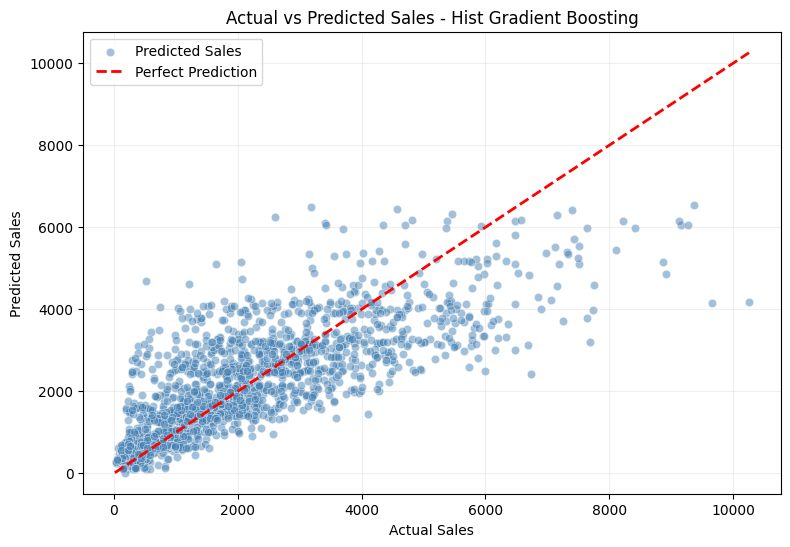

In [99]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=Y_test,
    y=Y_pred,
    color="steelblue",
    alpha=0.5,
    label="Predicted Sales"
)

min_val = min(Y_test.min(), Y_pred.min())
max_val = max(Y_test.max(), Y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Hist Gradient Boosting")

plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Prediction of Sales for new Stores 

In [100]:
new_store_df = pd.read_csv("./dataset/test.csv")

new_store_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5681 entries, 0 to 5680
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   No             5681 non-null   int64  
 1   ID             5681 non-null   object 
 2   Weight         4705 non-null   float64
 3   Fat            5681 non-null   object 
 4   Visibility     5681 non-null   float64
 5   Category       5681 non-null   object 
 6   Price          5681 non-null   float64
 7   Security       5681 non-null   object 
 8   StoreCode      5681 non-null   object 
 9   OperationYear  5681 non-null   int64  
 10  Size           4075 non-null   object 
 11  Area           5681 non-null   object 
 12  Type           5681 non-null   object 
 13  Sales          0 non-null      float64
dtypes: float64(4), int64(2), object(8)
memory usage: 621.5+ KB


In [101]:
predicted_sales = best_pipeline.predict(new_store_df)

In [102]:
new_store_df["Sales"] = predicted_sales.round(decimals=2)

new_store_df.sample(5)

,No,ID,Weight,Fat,Visibility,Category,Price,Security,StoreCode,OperationYear,Size,Area,Type,Sales
3684,3685,FDZ60,20.5000,Low Fat,0.1193,Baking Goods,108.8596,Prosegur,OUT013,1987,High,Tier 3,Supermarket Type1,1636.8300
5011,5012,FDH57,10.8950,Low Fat,0.0358,Fruits and Vegetables,130.5284,Prosegur,OUT045,2002,NaN,Tier 2,Supermarket Type1,2073.1800
1911,1912,FDR12,12.6000,Regular,0.0528,Baking Goods,170.3764,Prosegur,OUT010,1998,NaN,Tier 3,Grocery Store,308.0300
5528,5529,FDF50,4.9050,Low Fat,0.1172,Canned,198.2768,AHS,OUT013,1987,High,Tier 3,Supermarket Type1,3102.8500
5641,5642,NCI43,19.8500,Low Fat,0.0260,Household,49.8376,AHS,OUT049,1999,Medium,Tier 1,Supermarket Type1,818.9800


### - Exported predicted Sales in new file.

In [103]:
new_store_df.to_csv("./output/predicted_sales.csv", index=False)